<a href="https://colab.research.google.com/github/csu-techhub/QOS-Labs/blob/main/Lab3_extension_portfolio.ipynb" target="_parent">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Optional (Lab 3 extension) — From Max-Cut to Portfolio Selection with QAOA
**Quantum Optimization and Simulation — QAOA Laboratory Series**

In the lecture, QAOA split a **5-node graph** to maximize the cut. In this lab we use the *same* 5-qubit QAOA circuit on a real-life problem: an investor choosing **2 out of 5 stocks**. You will see that the recipe barely changes:

| | Max-Cut (lecture) | Portfolio (this lab) |
|---|---|---|
| 5 bits | 5 nodes | 5 stocks |
| bit $x_i = 1$ | node $i$ in group 1 | buy stock $i$ |
| what we score | number of cut edges | return and risk |
| QAOA steps | Step 1 Everyone on stage → Step 2 Judges' scores → Step 3 Crowd's applause | the same three steps, with Steps 1 and 3 adapted so that we always buy exactly 2 stocks |

> Bitstrings are written `x0 x1 x2 x3 x4` (stock 0 first), just like `00011` in the lecture. Qiskit prints bitstrings in the reverse order, so the helper `q0_first(...)` flips them for us.

## Learning objectives
- Recall the Max-Cut encoding: a bitstring, a score, a cost Hamiltonian $H_C$ built from $Z_iZ_j$ terms.
- Describe the **portfolio selection** problem as a bitstring problem: expected return $\mu_i$, covariance $\sigma_{ij}$, and the goal $\min\, q\,V(x) - R(x)$.
- Convert the goal into a cost Hamiltonian, and identify what is the **same** as Max-Cut ($Z_iZ_j$ terms → CNOT–Rz–CNOT) and what is **new** (single-qubit $Z_i$ terms → one Rz per qubit).
- Build the rule "buy exactly 2 stocks" into the circuit with a **Dicke starting state** and the **XY mixer**.
- Run QAOA on 5 qubits and check the result against the exact answer (only $2^5 = 32$ bitstrings).

In [1]:
# Run once in a fresh Google Colab session.
%pip -q install "pylatexenc" "qiskit~=2.5" "qiskit-aer~=0.17" scipy numpy pandas matplotlib networkx yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.6 MB/s eta 0:00:00


In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

SEED = 123
SHOTS = 2048

def run_counts(qc, shots=SHOTS):
    backend = AerSimulator()
    tqc = transpile(qc, backend, optimization_level=1)
    return backend.run(tqc, shots=shots, seed_simulator=SEED).result().get_counts()

def q0_first(qiskit_bits):
    # Qiskit prints q4 q3 q2 q1 q0; we write x0 x1 x2 x3 x4
    return qiskit_bits.replace(" ", "")[::-1]

## Recap: Max-Cut in one page
From the lecture:
- **Encoding.** Each of the 5 nodes belongs to group 0 or group 1, so a candidate answer is a 5-bit string such as `00011`. There are $2^5 = 32$ candidates.
- **Score.** `cut(x)` counts the edges whose two ends are in different groups, for example `cut(00101) = 3` and `cut(00011) = 6`.
- **Cost Hamiltonian.** Each edge contributes a $Z_iZ_j$ term:
$$H_C = \tfrac{1}{2}\left(-Z_0Z_3 - Z_0Z_4 - Z_1Z_3 - Z_1Z_4 - Z_2Z_3 - Z_2Z_4\right).$$
- **Cost operator.** $U_C(\gamma) = e^{-i\gamma H_C}$ tags every bitstring with a phase that depends on its score. On a circuit, each $Z_iZ_j$ term is a **CNOT–Rz–CNOT** block.
- **QAOA.** Step 1: $H$ gates put everyone on stage. Step 2: $U_C(\gamma)$, the judges' scores. Step 3: the mixer $R_x(2\beta)$ on every qubit, the crowd's applause. Then measure, and let a classical optimizer tune $\gamma, \beta$.

## The new problem: choose 2 of 5 stocks
An investor is considering **5 stocks** but wants to buy **exactly $K = 2$** of them, with the same amount of money in each. Why limit the number? Every stock held costs money and attention: transaction fees, research, monitoring and rebalancing. Small investors often cannot buy meaningful amounts of every stock anyway.

| bit | stock | business |
|---|---|---|
| $x_0$ | AAPL (Apple) | technology |
| $x_1$ | MSFT (Microsoft) | technology |
| $x_2$ | JPM (JPMorgan Chase) | banking |
| $x_3$ | XOM (Exxon Mobil) | energy |
| $x_4$ | KO (Coca-Cola) | consumer staples |

**The decision is a bitstring, just like Max-Cut.** For each stock, $x_i = 1$ means *buy it* and $x_i = 0$ means *skip it*. For example, `11000` means "buy AAPL and MSFT", and `01001` means "buy MSFT and KO".

There are again $2^5 = 32$ bitstrings, but only $\binom{5}{2} = 10$ of them contain exactly two 1s. That is the first difference from Max-Cut, where every bitstring is a valid answer.

**What makes a good choice?** We follow the classic mean–variance idea of Harry Markowitz and balance two goals:
1. **High expected return:** stocks that have tended to go up.
2. **Low risk:** a combination whose value does not swing around too much.


In [3]:
TICKERS = ["AAPL", "MSFT", "JPM", "XOM", "KO"]
SECTOR = {"AAPL": "Tech", "MSFT": "Tech", "JPM": "Finance", "XOM": "Energy", "KO": "Staples"}
SECTOR_COLOR = {"Tech": "tab:blue", "Finance": "tab:green", "Energy": "tab:red", "Staples": "tab:orange"}
colors = [SECTOR_COLOR[SECTOR[t]] for t in TICKERS]

N = 5          # number of stocks = number of qubits
K = 2          # number of stocks to buy
Q_RISK = 5.0   # risk aversion q (how much the investor dislikes risk)
START, END = "2023-01-01", "2025-12-31"

def names(bits):
    return [TICKERS[i] for i, b in enumerate(bits) if int(b) == 1]

print("Example: 01001 means buy", names("01001"))

Example: 01001 means buy ['MSFT', 'KO']


## Part A — Two numbers from price history: $\mu_i$ and $\sigma_{ij}$
We download 3 years of daily prices (the same window for everyone) and compute each day's return $r_t = P_t / P_{t-1} - 1$. There are about 252 trading days in a year, so 3 years give roughly 756 daily returns per stock. From them we compute two kinds of numbers:

- **Expected return $\mu_i$:** the average yearly gain of stock $i$ (the average daily return × 252). A higher $\mu_i$ means the stock has tended to go up more.
- **Covariance $\sigma_{ij}$:** how much stocks $i$ and $j$ move together (the covariance of their daily returns × 252).
  - **Positive:** they tend to rise and fall together.
  - **Near zero:** they move independently.
  - **Negative:** one tends to rise when the other falls.

  When $i = j$, $\sigma_{ii}$ is the **variance** of stock $i$: how much it swings on its own. Its square root $\sigma_i = \sqrt{\sigma_{ii}}$ is the **volatility**.

In the code, the $5 \times 5$ table of $\sigma_{ij}$ is the array `Sigma`, and the volatilities $\sigma_i$ are the array `sigma`.

The code gets real data from **Yahoo Finance**.

In [4]:
import yfinance as yf
raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
prices = raw["Close"].reindex(columns=TICKERS).dropna()
if len(prices) < 250:
    raise ValueError("insufficient market data")
returns = prices.pct_change().dropna()
DATA_SOURCE = f"Yahoo Finance, {prices.index.min().date()} to {prices.index.max().date()}"

mu = returns.mean().values * 252        # expected return mu_i
Sigma = returns.cov().values * 252      # covariance table: Sigma[i, j] = sigma_ij
sigma = np.sqrt(np.diag(Sigma))         # volatility: sigma[i] = sigma_i = sqrt(sigma_ii)
corr = returns.corr()

print("Data source:", DATA_SOURCE, "\n")
print(pd.DataFrame({"bit": [f"x{i}" for i in range(N)], "sector": [SECTOR[t] for t in TICKERS],
                    "expected return μ_i": mu.round(3), "volatility σ_i": sigma.round(3)}, index=TICKERS))
print("\nCovariance table σ_ij:")
print(pd.DataFrame(Sigma, index=TICKERS, columns=TICKERS).round(4))

Data source: Yahoo Finance, 2023-01-03 to 2025-12-30 

     bit   sector  expected return μ_i  volatility σ_i
AAPL  x0     Tech                0.300           0.256
MSFT  x1     Tech                0.274           0.232
JPM   x2  Finance                0.345           0.231
XOM   x3   Energy                0.103           0.226
KO    x4  Staples                0.077           0.147

Covariance table σ_ij:
        AAPL    MSFT     JPM     XOM      KO
AAPL  0.0656  0.0291  0.0180  0.0107  0.0047
MSFT  0.0291  0.0539  0.0135  0.0002 -0.0000
JPM   0.0180  0.0135  0.0533  0.0181  0.0036
XOM   0.0107  0.0002  0.0181  0.0511  0.0046
KO    0.0047 -0.0000  0.0036  0.0046  0.0217


Covariances are small numbers that are hard to compare by eye, so we also look at the **correlation** (covariance rescaled to lie between −1 and +1). The middle panel draws the stocks as a graph, next to the Max-Cut graph from the lecture:
- In Max-Cut, only **6** pairs of nodes are joined by an edge.
- In the portfolio problem, **every** pair of stocks has a covariance, so all **10** pairs are joined. A thicker, darker edge means the two stocks move together more strongly.

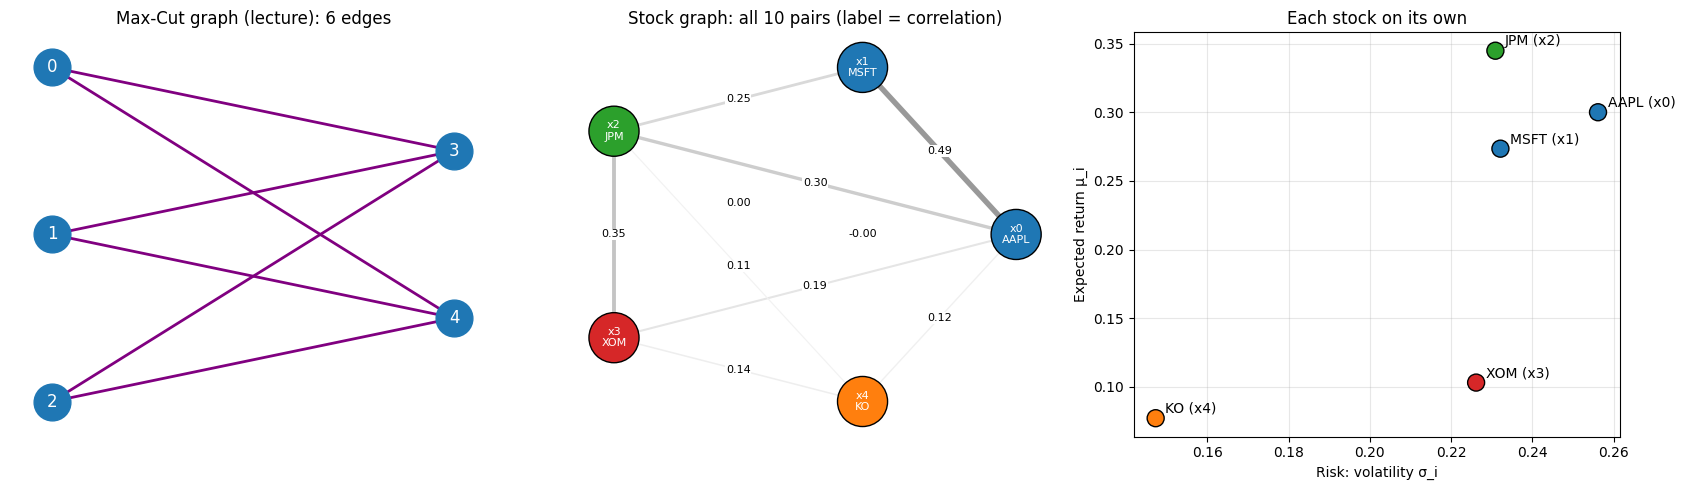

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (1) Max-Cut graph from the lecture
MC_EDGES = [(0, 3), (0, 4), (1, 3), (1, 4), (2, 3), (2, 4)]
G_mc = nx.Graph(MC_EDGES)
pos_mc = {0: (0, 2), 1: (0, 1), 2: (0, 0), 3: (1.4, 1.5), 4: (1.4, 0.5)}
nx.draw(G_mc, pos_mc, ax=axes[0], with_labels=True, node_color="tab:blue", node_size=700,
        font_color="white", edge_color="purple", width=2)
axes[0].set_title("Max-Cut graph (lecture): 6 edges")

# (2) Stock graph: every pair connected, edge width = correlation
G = nx.complete_graph(N)
pos = nx.circular_layout(G)
w = np.array([corr.values[i, j] for i, j in G.edges()])
nx.draw_networkx_edges(G, pos, ax=axes[1], width=8 * np.clip(w, 0, 1), edge_color=np.clip(w, 0, 1),
                       edge_cmap=plt.cm.Greys, edge_vmin=0, edge_vmax=1)
nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=colors, node_size=1300, edgecolors="black")
nx.draw_networkx_labels(G, pos, labels={i: f"x{i}\n{t}" for i, t in enumerate(TICKERS)},
                        ax=axes[1], font_size=8, font_color="white")
for (i, j), wij in zip(G.edges(), w):
    xm, ym = (pos[i] + pos[j]) / 2
    axes[1].text(xm, ym, f"{wij:.2f}", fontsize=8, ha="center", va="center",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
axes[1].set_title("Stock graph: all 10 pairs (label = correlation)"); axes[1].axis("off")

# (3) Risk-return map
axes[2].scatter(sigma, mu, s=150, c=colors, edgecolors="black", zorder=3)
for i, t in enumerate(TICKERS):
    axes[2].annotate(f"{t} (x{i})", (sigma[i], mu[i]), xytext=(7, 4), textcoords="offset points")
axes[2].set_xlabel("Risk: volatility σ_i"); axes[2].set_ylabel("Expected return μ_i")
axes[2].set_title("Each stock on its own"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### YOUR TURN A
1. Which pair of stocks has the **highest** correlation? Give a business reason why they move together.
2. In the covariance table $\sigma_{ij}$, which stock has the **smallest** covariances with all the others? Why might an investor like it even if its own return is low?

## Part B — Scoring a bitstring: $R(x)$ and $V(x)$
In Max-Cut, every bitstring got a score `cut(x)`. Here every bitstring gets two scores.

**Return, one term per bit.** With equal money in each stock bought, the portfolio return is the average of the chosen $\mu_i$:
$$R(x) = \frac{1}{K}\sum_i \mu_i\, x_i .$$
For `01001` (MSFT and KO): $R = (\mu_1 + \mu_4)/2$. Skipped stocks are multiplied by 0 and drop out.

**Risk, one term per pair.** The portfolio variance adds the covariances over every pair of stocks we hold:
$$V(x) = \frac{1}{K^2}\sum_i \sum_j \sigma_{ij}\, x_i x_j .$$
For `01001` (MSFT and KO): $V = (\sigma_{11}+\sigma_{44}+2\sigma_{14})/4$ because $x_1 x_1=x_4 x_4=x_1 x_4=1$ and all other $x_i x_j =0$.
Two own-variance terms plus a **together** term, $2\sigma_{ij}$:
 They rarely move together, so $\sigma_{14}$ is small. Their ups and downs partly cancel, and the risk stays **low**. This is **diversification**.

For `11000` (AAPL + MSFT): $V = (\sigma_{00}+\sigma_{11}+2\sigma_{01})/4$. Both are tech stocks that rise and fall together, so $\sigma_{01}$ is large and the together term pushes the risk **up**.

**The goal.** Combine the two scores into one cost:
$$\min_{x}\; q\,V(x) - R(x) \qquad\text{subject to}\qquad x_0 + x_1 + x_2 + x_3 + x_4 = 2 .$$
Minimizing $-R(x)$ is the same as maximizing the return, while $q\,V(x)$ punishes risk. The number $q \ge 0$ is the investor's **risk aversion**:
- $q = 0$: risk is ignored, so we just buy the two highest-return stocks.
- Larger $q$: we prefer safer, well-diversified pairs.

Since there are only 32 bitstrings, we can score them all and know the true answer before running any quantum circuit, just like checking `cut(x)` for all 32 cuts.

In [6]:
def R_of(x):  x = np.asarray(x); return mu @ x / K
def V_of(x):  x = np.asarray(x); return x @ Sigma @ x / K**2
def objective(x, q=Q_RISK): return q * V_of(x) - R_of(x)

ALL_X = np.array(list(itertools.product([0, 1], repeat=N)))   # each row is x0 ... x4
BITS = ["".join(map(str, x)) for x in ALL_X]
VALID = [s for s in BITS if s.count("1") == K]

table = pd.DataFrame({"stocks": [" + ".join(names(s)) for s in VALID],
                      "return R": [R_of([int(c) for c in s]) for s in VALID],
                      "risk V": [V_of([int(c) for c in s]) for s in VALID],
                      f"cost qV − R (q={Q_RISK})": [objective([int(c) for c in s]) for s in VALID]},
                     index=VALID).sort_values(f"cost qV − R (q={Q_RISK})")
OPT_BITS = table.index[0]
print(f"All {len(VALID)} valid portfolios, best first:")
print(table.round(4))
print(f"\nBest portfolio: {OPT_BITS} = {names(OPT_BITS)}")

All 10 valid portfolios, best first:
            stocks  return R  risk V  cost qV − R (q=5.0)
01100   MSFT + JPM    0.3092  0.0335              -0.1415
10100   AAPL + JPM    0.3225  0.0387              -0.1288
00101     JPM + KO    0.2110  0.0206              -0.1082
01001    MSFT + KO    0.1753  0.0189              -0.0809
10001    AAPL + KO    0.1886  0.0242              -0.0677
11000  AAPL + MSFT    0.2868  0.0444              -0.0646
01010   MSFT + XOM    0.1883  0.0264              -0.0565
00110    JPM + XOM    0.2240  0.0351              -0.0483
10010   AAPL + XOM    0.2016  0.0346              -0.0288
00011     XOM + KO    0.0901  0.0205               0.0125

Best portfolio: 01100 = ['MSFT', 'JPM']


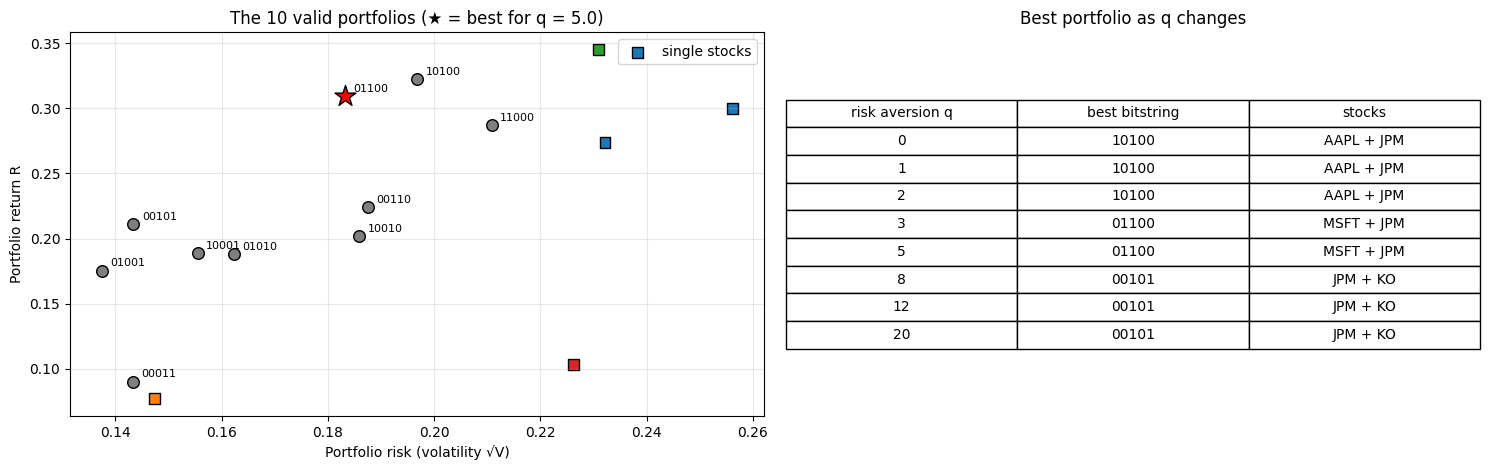

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Left: return vs risk of the 10 valid portfolios
for s in VALID:
    x = [int(c) for c in s]
    best = s == OPT_BITS
    axes[0].scatter(np.sqrt(V_of(x)), R_of(x), s=250 if best else 70, marker="*" if best else "o",
                    c="red" if best else "tab:gray", edgecolors="black", zorder=3)
    axes[0].annotate(s, (np.sqrt(V_of(x)), R_of(x)), xytext=(6, 3), textcoords="offset points", fontsize=8)
axes[0].scatter(sigma, mu, c=colors, marker="s", s=60, edgecolors="black", label="single stocks")
axes[0].set_xlabel("Portfolio risk (volatility √V)"); axes[0].set_ylabel("Portfolio return R")
axes[0].set_title(f"The 10 valid portfolios (★ = best for q = {Q_RISK})")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Right: how the best pair changes with risk aversion q
q_values = [0, 1, 2, 3, 5, 8, 12, 20]
winners = [min(VALID, key=lambda s: objective([int(c) for c in s], q)) for q in q_values]
axes[1].axis("off")
axes[1].table(cellText=[[q, w, " + ".join(names(w))] for q, w in zip(q_values, winners)],
              colLabels=["risk aversion q", "best bitstring", "stocks"], loc="center", cellLoc="center").scale(1, 1.6)
axes[1].set_title("Best portfolio as q changes")
plt.tight_layout(); plt.show()

### YOUR TURN B
1. Using the covariance table from Part A, compute $V$ **by hand** for `11000` (AAPL + MSFT) and for `01001` (MSFT + KO) with $V = (\sigma_{ii} + \sigma_{jj} + 2\sigma_{ij})/4$. Which term makes the difference?
2. At $q = 0$ the best pair is simply the two highest returns. Why does the answer change as $q$ grows? Which stock from YOUR TURN A2 shows up?

## Part C — From the goal to a cost Hamiltonian $H_C$
As in Max-Cut, we turn the cost into a Hamiltonian, so that the "judges" (Step 2) can score every bitstring. The cost is simply the goal from Part B:
$$C(x) = q\,V(x) - R(x).$$
There is **no extra term for the rule** "buy exactly 2 stocks". We will build that rule into the circuit itself in Part D below. That keeps the cost as simple as Max-Cut's.

Writing out $V(x)$ and $R(x)$, and using $x_i^2 = x_i$ (a bit squared is itself), the cost has one-bit terms and two-bit terms:
$$C(x) = \sum_i a_i\, x_i + \sum_{i<j} b_{ij}\, x_i x_j, \qquad a_i = -\frac{\mu_i}{K} + \frac{q\,\sigma_{ii}}{K^2}, \qquad b_{ij} = \frac{2q\,\sigma_{ij}}{K^2}.$$
- $a_i$: a good return lowers the cost (−), and the stock's own variance raises it (+).
- $b_{ij}$: buying two stocks that move together raises the cost.

**From bits to qubits.** Exactly as in Max-Cut, a bit is read from a Pauli $Z$: $Z_i = +1$ for $|0\rangle$ and $Z_i = -1$ for $|1\rangle$, so $x_i = (1 - Z_i)/2$. Substituting gives
$$H_C = \sum_{i<j} J_{ij}\, Z_iZ_j \;+\; \sum_i h_i\, Z_i, \qquad J_{ij} = \frac{b_{ij}}{4}, \qquad h_i = -\frac{a_i}{2} - \sum_{j \ne i}\frac{b_{ij}}{4},$$
up to a constant, which only adds a **global phase** and is dropped, as in the lecture.

**Compare with Max-Cut.** The same substitution turned each Max-Cut edge term into $\tfrac{1}{2}(1 - Z_iZ_j)$. Its one-bit parts canceled, so Max-Cut had **only** $Z_iZ_j$ terms. Here they do not cancel:

| | Max-Cut | Portfolio |
|---|---|---|
| Cost | $-\text{cut}(x)$ | $q\,V(x) - R(x)$ |
| $Z_iZ_j$ terms | 6 (one per edge), coefficient $-\tfrac12$ | 10 (every pair), coefficient $J_{ij}$ from covariance |
| $Z_i$ terms | none | **new:** 5 (one per stock), coefficient $h_i$ from return and own variance |
| Circuit (Step 2) | CNOT–Rz–CNOT per edge | CNOT–Rz–CNOT per pair **+ one Rz per qubit** |

In [8]:
# One-bit and two-bit coefficients of the cost C(x) = qV(x) - R(x)
a = -mu / K + Q_RISK * np.diag(Sigma) / K**2
b = np.zeros((N, N))
for i in range(N):
    for j in range(i + 1, N):
        b[i, j] = 2 * Q_RISK * Sigma[i, j] / K**2

# Ising coefficients of H_C
J = b / 4
h = np.array([-a[i] / 2 - (b[i, :].sum() + b[:, i].sum()) / 4 for i in range(N)])

COST = {s: objective(x) for s, x in zip(BITS, ALL_X)}

# Check: H_C (+ a constant) reproduces the cost of every bitstring
def ising_energy(x):
    z = 1 - 2 * np.asarray(x)
    return sum(J[i, j] * z[i] * z[j] for i in range(N) for j in range(i + 1, N)) + h @ z
diff = [COST[s] - ising_energy(x) for s, x in zip(BITS, ALL_X)]
print(f"H_C matches the cost of all 32 bitstrings up to a constant: {np.ptp(diff) < 1e-9}")

terms = [f"{J[i, j]:+.3f} Z{i}Z{j}" for i in range(N) for j in range(i + 1, N)] + \
        [f"{h[i]:+.3f} Z{i}" for i in range(N)]
print("\nH_C =", " ".join(terms[:5]), "\n     ", " ".join(terms[5:10]), "\n     ", " ".join(terms[10:]))

cheapest = min(COST, key=COST.get)
print(f"\nCheapest of all 32 bitstrings: {cheapest} = {names(cheapest)}, "
      f"buys {cheapest.count('1')} stock(s) -> {'valid' if cheapest.count('1') == K else 'NOT a valid portfolio'}")
print(f"Best valid portfolio (Part B): {OPT_BITS} = {names(OPT_BITS)}")

H_C matches the cost of all 32 bitstrings up to a constant: True

H_C = +0.018 Z0Z1 +0.011 Z0Z2 +0.007 Z0Z3 +0.003 Z0Z4 +0.008 Z1Z2 
      +0.000 Z1Z3 -0.000 Z1Z4 +0.011 Z2Z3 +0.002 Z2Z4 +0.003 Z3Z4 
      -0.005 Z0 +0.008 Z1 +0.020 Z2 -0.027 Z3 -0.002 Z4

Cheapest of all 32 bitstrings: 01101 = ['MSFT', 'JPM', 'KO'], buys 3 stock(s) -> NOT a valid portfolio
Best valid portfolio (Part B): 01100 = ['MSFT', 'JPM']


**The cost alone does not know the rule.** The cheapest of all 32 bitstrings may well buy only **one** stock, which breaks "buy exactly 2". In Max-Cut this never mattered, because every bitstring was a valid answer. Here, QAOA must stay among the 10 valid portfolios, and we will make sure of that with the circuit in Part D.

**Rescaling and gates.** The $h_i$ and $J_{ij}$ above have awkward sizes. Dividing $H_C$ by a constant only stretches the $\gamma$ axis; the best bitstring stays the same. We divide by the largest coefficient so that all coefficients lie between −1 and 1, like the $\pm\tfrac12$ of Max-Cut. Then, for one value of $\gamma$:
- **Same as Max-Cut:** each $J_{ij} Z_iZ_j$ becomes a CNOT–$R_z(2\gamma J_{ij})$–CNOT block. (In the lecture, $J = -\tfrac12$ gave $R_z(-\gamma)$.)
- **New:** each $h_i Z_i$ becomes a single $R_z(2\gamma h_i)$ on qubit $i$.

In [9]:
SCALE = max(np.abs(h).max(), np.abs(J).max())
h_n, J_n = h / SCALE, J / SCALE

def cost_layer(qc, gamma):
    for i in range(N):
        for j in range(i + 1, N):
            qc.cx(i, j)
            qc.rz(2 * gamma * J_n[i, j], j)     # same as Max-Cut
            qc.cx(i, j)
    for i in range(N):
        qc.rz(2 * gamma * h_n[i], i)           # NEW: one Rz per stock
    qc.barrier()

### YOUR TURN C
1. Look at the printed $H_C$. Which terms are like Max-Cut, and which are new?
2. A stock with a **high** expected return makes $a_i$ more negative. Does that make $h_i$ larger or smaller? Which bit value ($Z_i = +1$ or $-1$) lowers the energy $h_i Z_i$ when $h_i > 0$?
3. Why can't we simply run the Max-Cut circuit with this $H_C$? (Hint: what is the cheapest of all 32 bitstrings?)

## Part D — QAOA with the rule built into the circuit
We keep the three steps from the lecture, but change Steps 1 and 3 so that QAOA **never leaves the valid portfolios**:

1. **Everyone (valid) on stage.** In Max-Cut, $H$ gates gave all 32 bitstrings equal probability. Here we start in an equal superposition of only the **10 bitstrings with exactly two 1s** (called a *Dicke state*). We prepare it directly with `initialize`, which is convenient for simulation.
2. **Judges' scores.** Exactly as in Max-Cut: the cost layer $e^{-i\gamma H_C}$ from Part C tags each portfolio with a phase that depends on its cost.
3. **Crowd's applause, with the XY mixer.** The Max-Cut mixer $R_x$ flips single bits, so it could turn `01001` (2 stocks) into `01000` (1 stock). The **XY mixer** acts on *pairs* of qubits and swaps $|01\rangle \leftrightarrow |10\rangle$. It moves a "1" from one stock to another, for example `01001` → `00101` (MSFT + KO → JPM + KO), so the number of stocks bought **never changes**.

Every measurement therefore buys exactly 2 stocks, and the judges only have to compare return and risk. This version of QAOA is often called the **Quantum Alternating Operator Ansatz**.

| Step | Max-Cut | Portfolio |
|---|---|---|
| 1. Everyone on stage | $H$ on every qubit (all 32 bitstrings) | Dicke state (only the 10 valid portfolios) |
| 2. Judges' scores | $e^{-i\gamma H_C}$ | $e^{-i\gamma H_C}$ (same idea, plus single-qubit $R_z$) |
| 3. Crowd's applause | $R_x(2\beta)$ on every qubit | XY mixer on neighboring pairs |

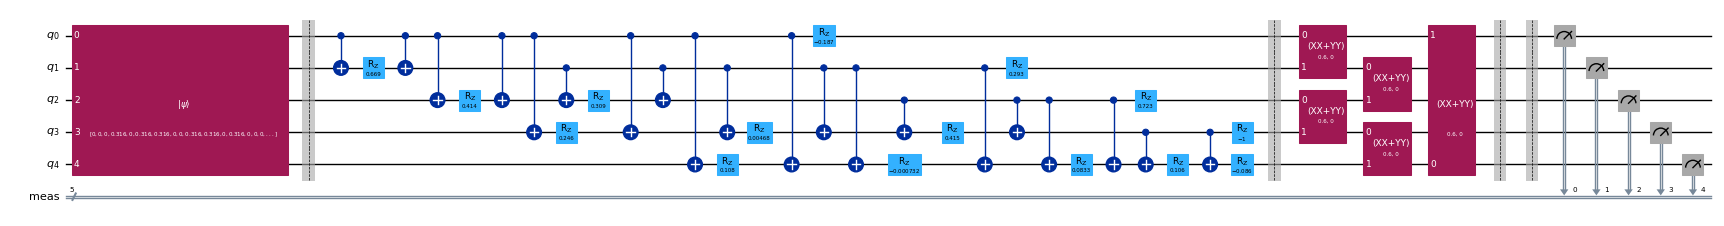

In [10]:
from qiskit.circuit.library import XXPlusYYGate

dicke = np.array([1.0 if bin(k).count("1") == K else 0.0 for k in range(2**N)])
dicke /= np.linalg.norm(dicke)          # equal superposition of the 10 valid portfolios

def xy_mixer(qc, beta):
    # swap |01> <-> |10> on neighboring qubits around a ring
    for pair in [(0, 1), (2, 3), (1, 2), (3, 4), (4, 0)]:
        qc.append(XXPlusYYGate(2 * beta), list(pair))
    qc.barrier()

def build_qaoa(gammas, betas):
    qc = QuantumCircuit(N)
    qc.initialize(dicke)                 # Step 1: only the valid portfolios on stage
    qc.barrier()
    for gamma, beta in zip(gammas, betas):
        cost_layer(qc, gamma)            # Step 2: judges' scores
        xy_mixer(qc, beta)               # Step 3: applause that never changes the number of stocks
    qc.measure_all()
    return qc

def analyze(counts):
    # average cost, P(exactly K stocks), P(best portfolio)
    total = sum(counts.values())
    E = p_valid = p_opt = 0.0
    for raw, c in counts.items():
        s = q0_first(raw)
        E += COST[s] * c / total
        p_valid += (s.count("1") == K) * c / total
        p_opt += (s == OPT_BITS) * c / total
    return E, p_valid, p_opt

def expected_cost(params):
    p = len(params) // 2
    return analyze(run_counts(build_qaoa(params[:p], params[p:]), shots=4096))[0]

build_qaoa([0.5], [0.3]).draw("mpl", fold=-1, scale=0.5)

### Close the hybrid loop with COBYLA ($p = 1$, then $p = 2$)
As in the Max-Cut lab, we measure, compute the average cost $\langle C \rangle$ of the samples, and let COBYLA tune $\gamma$ and $\beta$. The only change is the direction: Max-Cut **maximized** the cut, and here we **minimize** the cost. A quick coarse grid picks a good starting point for COBYLA.

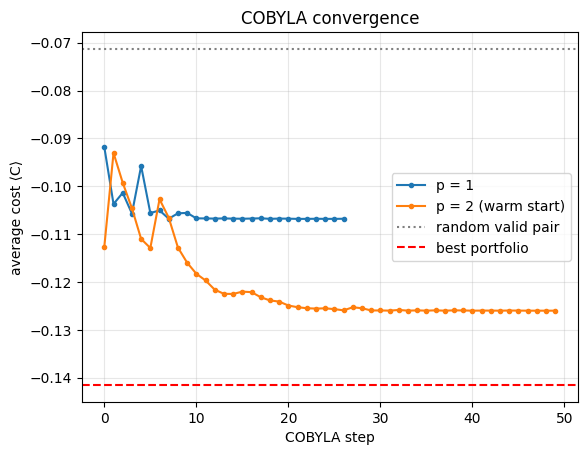

In [11]:
# Coarse grid for a starting point, then COBYLA for p = 1; p = 2 warm-started from p = 1
grid = [(expected_cost([g, bt]), g, bt) for g in np.linspace(-np.pi, np.pi, 9)
        for bt in np.linspace(-np.pi / 2, np.pi / 2, 7)]
_, g0, bt0 = min(grid)

history = {1: [], 2: []}
def make_f(p):
    def f(params):
        v = expected_cost(params); history[p].append(v); return v
    return f

res_p1 = minimize(make_f(1), x0=[g0, bt0], method="COBYLA", options={"maxiter": 60, "rhobeg": 0.2})
g1, b1 = res_p1.x
res_p2 = minimize(make_f(2), x0=[0.6 * g1, 1.2 * g1, 1.2 * b1, 0.6 * b1], method="COBYLA",
                  options={"maxiter": 150, "rhobeg": 0.3})

random_cost = np.mean([COST[s] for s in VALID])    # average cost of a random valid pair
plt.plot(history[1], ".-", label="p = 1")
plt.plot(history[2], ".-", label="p = 2 (warm start)")
plt.axhline(random_cost, color="gray", ls=":", label="random valid pair")
plt.axhline(COST[OPT_BITS], color="red", ls="--", label="best portfolio")
plt.xlabel("COBYLA step"); plt.ylabel("average cost ⟨C⟩"); plt.title("COBYLA convergence")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [13]:
counts = {}
print(f"{'':20}{'⟨C⟩':>8}{'P(exactly 2)':>15}{'P(best)':>10}")
print(f"{'random guess':20}{np.mean(list(COST.values())):8.3f}{len(VALID) / 2**N:15.3f}{1 / 2**N:10.3f}")
print(f"{'random valid pair':20}{random_cost:8.3f}{1.0:15.3f}{1 / len(VALID):10.3f}")
for label, res in {"p = 1": res_p1, "p = 2": res_p2}.items():
    p = len(res.x) // 2
    counts[label] = run_counts(build_qaoa(res.x[:p], res.x[p:]), shots=8192)
    E, pv, po = analyze(counts[label])
    print(f"{'QAOA ' + label:20}{E:8.3f}{pv:15.3f}{po:10.3f}")

c = counts["p = 2"]; total = sum(c.values())
prob = {s: 0.0 for s in VALID}
for raw, v in c.items():
    prob[q0_first(raw)] += v / total

                         ⟨C⟩   P(exactly 2)   P(best)
random guess          -0.057          0.312     0.031
random valid pair     -0.071          1.000     0.100
QAOA p = 1            -0.107          1.000     0.225
QAOA p = 2            -0.126          1.000     0.371


Compare this with the Max-Cut result from the lecture. There, the judges rewarded large cuts and QAOA made the best cut the most likely outcome. Here the judges reward a good balance of return and risk, and QAOA makes the best **portfolio** the most likely outcome, while never producing an invalid one.

### YOUR TURN D
1. Why is P(exactly 2) equal to 1 for every QAOA run, even with shot noise?
2. How much more often does QAOA output the best portfolio than a random valid pair (1/10)? Does $p = 2$ help?
3. In the right panel, where is most of the probability? Does it follow the ranking from Part B?

## Part E — What did we buy?
In practice we keep the **most frequently measured bitstring**. Let's compare it with the exact answer from Part B and with simply buying all 5 stocks equally.

QAOA's pick (most frequent, p = 2): 10100 = ['AAPL', 'JPM']
Exact best portfolio (Part B)      : 01100 = ['MSFT', 'JPM']
Match: False

                             expected return  volatility
QAOA pick                              0.322       0.197
all 5 stocks, equal amounts            0.220       0.134


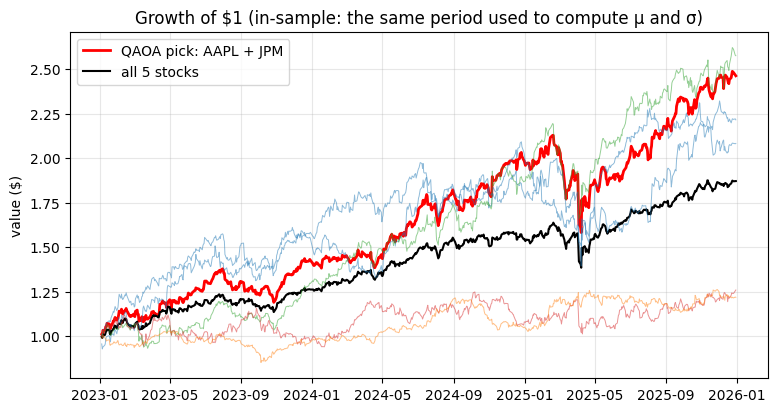

In [14]:
x_qaoa_bits = max(prob, key=prob.get)
x_qaoa = np.array([int(ch) for ch in x_qaoa_bits])

print(f"QAOA's pick (most frequent, p = 2): {x_qaoa_bits} = {names(x_qaoa_bits)}")
print(f"Exact best portfolio (Part B)      : {OPT_BITS} = {names(OPT_BITS)}")
print(f"Match: {x_qaoa_bits == OPT_BITS}\n")

def stats(x, k):
    x = np.asarray(x, float); return mu @ x / k, np.sqrt(x @ Sigma @ x) / k
rows = {"QAOA pick": stats(x_qaoa, K), "all 5 stocks, equal amounts": stats(np.ones(N), N)}
print(pd.DataFrame(rows, index=["expected return", "volatility"]).T.round(3))

pick = names(x_qaoa_bits)
plt.figure(figsize=(9, 4.5))
plt.plot((1 + returns[pick].mean(axis=1)).cumprod(), color="red", lw=2, label=f"QAOA pick: {' + '.join(pick)}")
plt.plot((1 + returns.mean(axis=1)).cumprod(), color="black", lw=1.5, label="all 5 stocks")
for t in TICKERS:
    plt.plot((1 + returns[t]).cumprod(), color=SECTOR_COLOR[SECTOR[t]], lw=0.7, alpha=0.5)
plt.title("Growth of $1 (in-sample: the same period used to compute μ and σ)")
plt.ylabel("value ($)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

> **Caution:** this chart is *in-sample*. The same prices were used to compute $\mu_i$ and $\sigma_{ij}$ and to judge the result, so it is guaranteed to look good. A fair test would choose the portfolio with one period's data and check it on a later period.

## Reflection: why does this matter?
With 5 stocks we could simply check all 10 valid pairs by hand. Real investors face much bigger choices: picking 30 stocks out of 500 gives about $10^{48}$ possible portfolios, far too many to check one by one. The problem keeps exactly the same shape, though: one qubit per stock, a $Z_iZ_j$ term for every pair, and a $Z_i$ term for every stock. That is why portfolio selection is one of the most studied real-world applications of QAOA.

**What you reused from Max-Cut:** the bitstring encoding, the substitution $x_i = (1 - Z_i)/2$, CNOT–Rz–CNOT blocks for $Z_iZ_j$, the three QAOA steps, and the COBYLA loop.

**What was new:** single-qubit $R_z$ terms (from returns and own risk), a fully connected graph with weighted edges (covariances), and a rule, "buy exactly $K$", built into the circuit with a Dicke starting state and the XY mixer.

**Going further.** Another common way to handle the rule is to add a penalty $\lambda\left(\sum_i x_i - K\right)^2$ to the cost and keep the Max-Cut $R_x$ mixer. It works, but the penalty must outweigh every return/risk difference, so it tends to drown out the very differences QAOA is trying to find. In quantum optimization, **building constraints into the circuit usually beats penalizing them**.


<details>
<summary><b>Suggested answers</b></summary>

**YOUR TURN A**
1. Usually AAPL–MSFT: both are large tech companies driven by the same factors (tech spending, interest-rate sensitivity of growth stocks, market sentiment toward tech).
2. Usually KO. It has a low volatility of its own, and consumer staples sell in good times and bad, so its covariances with the other stocks are the smallest. Adding it to a portfolio adds little risk and partly cancels the swings of the other stock, which is valuable even with a modest return.

**YOUR TURN B**
1. The own-variance terms are similar in size; the difference comes from the together term $2\sigma_{ij}$, which is much larger for AAPL–MSFT than for MSFT–KO.
2. As $q$ grows, risk counts more, so pairs with a large together term (AAPL + MSFT) lose and diversified pairs containing the weakly linked stock (often KO) win.

**YOUR TURN C**
1. The 10 $Z_iZ_j$ terms are like Max-Cut (but on every pair, with weights from covariance). The 5 single $Z_i$ terms are new; they come from returns and each stock's own variance.
2. A more negative $a_i$ makes $h_i = -a_i/2 + \dots$ **larger**. When $h_i > 0$, the energy $h_i Z_i$ is lowest for $Z_i = -1$, i.e. $x_i = 1$: buy the stock.
3. The cost does not know the rule: the cheapest of all 32 bitstrings typically buys just one stock (e.g. `01000`). The Max-Cut circuit ($H$ start, $R_x$ mixer) explores all 32 bitstrings and would drift toward such invalid answers. The Dicke start and the XY mixer keep QAOA on the 10 valid portfolios.

**YOUR TURN D**
1. The starting state contains only bitstrings with two 1s, and every XY gate only swaps a 1 and a 0 between two qubits. The number of 1s is conserved exactly, so every measurement buys exactly 2 stocks (on an ideal simulator; noise on real hardware can still break this).
2. Typically 2–3× at $p = 1$ and about 5× at $p = 2$ (exact numbers depend on the data and the optimizer run).
3. Most of the probability is on the left (the best portfolios), well above the 1/10 line, roughly following the Part B ranking; the best portfolio is usually the most likely outcome.

</details>